# A5-1 — 한 단계씩 만드는 신용 점수·연체 예측

**목표:** 같은 고객 정보로 숫자(회귀)와 연체 여부(분류)를 예측하고, 사람이 만든 규칙보다 학습이 어떤 점에서 나은지 수치로 설명한다.

이 노트북은 처음 배우는 과정을 펼쳐 쓰고, 반복을 경험한 뒤 Pipeline과 함수로 묶는다. 기존 `analysis_report.ipynb`는 최종 보고서로 유지한다.

**진행:** 데이터 → 분할 → 규칙 → 분류 하나 완성 → Pipeline → 불균형 → 회귀·규제 → 앙상블·튜닝 → 오류·임계값 → 보너스·기존 코드 연결.

프로젝트의 가상환경 커널을 선택하고 위에서부터 실행한다. 새 커널에서 **Restart & Run All**도 가능하다. 5-fold 탐색과 학습 곡선에는 시간이 걸린다. 기본 CPU 사용은 2코어 이하다. 외부 데이터와 딥러닝은 사용하지 않는다. 그림의 축은 폰트 호환성을 위해 영어로 쓴다.

각 설명의 **확인 질문**에는 먼저 자신의 말로 답해 본 뒤, 접힌 답을 연다. 중간 결과를 Test로 관찰하더라도 설정 선택은 Train 교차검증으로만 한다. 원본 CSV는 수정하지 않는다.

## 0. 준비 — 도구와 폴더

이번 질문: 노트북은 어디에서 데이터와 코드를 찾는가?

현재 폴더 또는 상위 폴더에서 `data_gen.py`와 `src/`가 함께 있는 A5-1 루트를 찾는다. `sys.path`는 마지막 모듈화 실습에서 `src`를 읽기 위한 검색 경로다. 머신러닝 계산은 다음 장부터 시작한다.

In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_root = None
for candidate_folder in [Path.cwd()] + list(Path.cwd().parents):
    if (candidate_folder / "data_gen.py").is_file() and (candidate_folder / "src").is_dir():
        project_root = candidate_folder
        break

if project_root is None:
    raise FileNotFoundError("A5-1 폴더를 찾지 못했습니다. A5-1 또는 notebooks에서 실행하세요.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

RANDOM_STATE = 42
pd.set_option("display.precision", 4)
print("프로젝트:", project_root.name)
print("Python 버전:", sys.version.split()[0])

프로젝트: A5-1
Python 버전: 3.12.13


## 1. 데이터 — 입력과 정답 구별

제공된 생성 코드는 소득·부채 비율·연체 횟수에 노이즈를 더해 신용 점수를 만들고, 그 점수 하위 15% 중 약 80%를 연체로 표시한다. 약 12%가 연체인 이유다. 생성 코드의 설명 주석보다 실제 연산을 기준으로 읽는다.

CSV가 없을 때만 제공된 `data_gen.py`를 실행한다. 생성 과정을 직접 시연하려면 프로젝트 루트 터미널에서 `uv run python data_gen.py`를 먼저 실행한다. 기존 CSV는 아래 셀에서 덮어쓰지 않는다.

In [2]:
data_path = project_root / "finance_data.csv"
if not data_path.exists():
    subprocess.run([sys.executable, str(project_root / "data_gen.py")],
                   cwd=project_root, check=True)

customers = pd.read_csv(data_path)
print("고객 수:", len(customers))
print("결측치 수:", customers.isna().sum().sum())
print("연체 비율:", customers["is_overdue"].mean())
assert len(customers) == 10_000
display(customers.head())

고객 수: 10000
결측치 수: 0
연체 비율: 0.1201


,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m,credit_score,is_overdue
0,50,3406.0,54,0.29,1,1,295.0,0
1,25,2161.0,7,0.78,2,0,259.0,1
2,56,6390.0,83,0.88,9,2,323.0,0
3,54,2821.0,10,0.01,2,2,377.0,0
4,50,4925.0,90,0.06,7,1,395.0,0


In [3]:
feature_columns = [
    "age", "annual_income", "spending_score", "debt_ratio",
    "credit_card_count", "overdue_count_6m",
]
X = customers[feature_columns]
y_classification = customers["is_overdue"]
y_regression = customers["credit_score"]

display(X.head())
display(customers[["credit_score", "is_overdue"]].head())

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
0,50,3406.0,54,0.29,1,1
1,25,2161.0,7,0.78,2,0
2,56,6390.0,83,0.88,9,2
3,54,2821.0,10,0.01,2,2
4,50,4925.0,90,0.06,7,1


,credit_score,is_overdue
0,295.0,0
1,259.0,1
2,323.0,0
3,377.0,0
4,395.0,0


**출력 읽기:** X는 예측할 때 받을 6개 정보, y는 맞혀야 할 정답이다. 회귀·분류가 같은 X를 사용한다. 정답 두 열은 X에서 제외한다. 특히 `credit_score`로 연체 라벨을 생성했으므로 분류 입력에 넣으면 정답 누수다.

**확인 질문:** 신용 점수가 숫자이고 연체 여부도 0/1 숫자인데 왜 문제 유형이 다른가?
<details><summary>답 확인</summary>신용 점수는 수치의 크기와 오차를 예측한다. 0/1은 정상/연체라는 범주의 표기다. 숫자로 저장됐는지가 아니라 무엇을 예측하고 어떻게 평가하는지가 다르다.</details>

## 2. 분할 — 공부할 데이터와 평가할 데이터

8:2로 한 번 나누고, 두 문제에 같은 고객 행을 사용한다. `stratify`는 연체 비율을 비슷하게 유지하고, `random_state=42`는 분할을 재현한다. Train 내부를 다시 나누는 교차검증의 Validation과 최종 Test는 역할이 다르다.

In [4]:
from sklearn.model_selection import train_test_split

train_indices, test_indices = train_test_split(
    customers.index, test_size=0.2, random_state=RANDOM_STATE,
    stratify=y_classification,
)
X_train = X.loc[train_indices]
X_test = X.loc[test_indices]
y_classification_train = y_classification.loc[train_indices]
y_classification_test = y_classification.loc[test_indices]
y_regression_train = y_regression.loc[train_indices]
y_regression_test = y_regression.loc[test_indices]

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "overdue_rate": [y_classification_train.mean(), y_classification_test.mean()],
}, index=["Train", "Test"])
display(split_summary)
assert set(train_indices).isdisjoint(test_indices)

,rows,overdue_rate
Train,8000,0.1201
Test,2000,0.1200


## 3. 사람이 정한 기준선

이번 질문: 학습하지 않고 if문으로만 예측하면 얼마나 맞힐까?

아래 6개 조건 중 하나라도 해당하면 1(연체), 모두 해당하지 않으면 0(정상)이다. 기존 보고서의 규칙과 같다. `apply(..., axis=1)`은 고객 한 행씩 함수에 전달한다.

In [5]:
def predict_by_rules(customer):
    if customer["overdue_count_6m"] >= 2:
        return 1
    if customer["debt_ratio"] > 0.8:
        return 1
    if customer["annual_income"] < 3000:
        return 1
    if customer["overdue_count_6m"] >= 1 and customer["debt_ratio"] > 0.6:
        return 1
    if customer["annual_income"] < 4000 and customer["debt_ratio"] > 0.5:
        return 1
    if customer["credit_card_count"] >= 8:
        return 1
    return 0

rule_predictions = X_test.apply(predict_by_rules, axis=1)
display(rule_predictions.head())

5911    1
3120    0
8838    1
8399    1
6896    1
dtype: int64

AUC는 0/1 판정과 달리 위험 순서를 평가한다. 그래서 규칙에 걸린 개수를 점수로 사용한다. 이 값은 실제 연체 확률이 아니다. 조건식의 True를 정수 1로 바꿔 더한다.

In [6]:
def count_risk_rules(customer):
    count = 0
    count += int(customer["overdue_count_6m"] >= 2)
    count += int(customer["debt_ratio"] > 0.8)
    count += int(customer["annual_income"] < 3000)
    count += int(customer["overdue_count_6m"] >= 1 and customer["debt_ratio"] > 0.6)
    count += int(customer["annual_income"] < 4000 and customer["debt_ratio"] > 0.5)
    count += int(customer["credit_card_count"] >= 8)
    return count

rule_scores = X_test.apply(count_risk_rules, axis=1)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

rule_result = {
    "model": "Rules",
    "accuracy": accuracy_score(y_classification_test, rule_predictions),
    "precision": precision_score(y_classification_test, rule_predictions, zero_division=0),
    "recall": recall_score(y_classification_test, rule_predictions),
    "f1": f1_score(y_classification_test, rule_predictions),
    "roc_auc": roc_auc_score(y_classification_test, rule_scores),
}
display(pd.DataFrame([rule_result]))

,model,accuracy,precision,recall,f1,roc_auc
0,Rules,0.513,0.1947,0.975,0.3245,0.8589


**출력 읽기:** Recall은 높지만 Precision이 낮다. 연체를 많이 찾으려고 정상 고객까지 많이 걸러낸다.

**확인 질문:** 모두 정상이라고 예측하면 Accuracy와 F1은 어떨까? 실행 전에 예상한다.

In [7]:
all_normal_predictions = np.zeros(len(y_classification_test), dtype=int)
print("모두 정상 — Accuracy:", accuracy_score(y_classification_test, all_normal_predictions))
print("모두 정상 — F1:", f1_score(y_classification_test, all_normal_predictions, zero_division=0))

모두 정상 — Accuracy: 0.88
모두 정상 — F1: 0.0


<details><summary>답 확인</summary>Accuracy는 약 88%지만 연체자를 한 명도 찾지 못해 F1은 0이다. Precision은 위험 판정의 신뢰도, Recall은 실제 연체자를 찾은 비율, F1은 둘의 조화평균이다. ROC-AUC는 임계값 하나에 고정되지 않은 순위 구분 능력이다. 어떤 지표 하나만으로 운영 결정을 내리지 않는다.</details>

## 4. 분류 하나 완성 — 전처리 → 학습 → 예측 → 평가

처음에는 원본 6개 수치형 변수만 사용한다. 결측치 중앙값과 표준화의 평균·표준편차는 **Train에서만** 배운다. `fit_transform`은 배우고 바꾸기, `transform`은 이미 배운 기준으로 바꾸기다. 원본 데이터에는 결측치가 없어도 처리 단계를 구성한다.

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_prepared = scaler.fit_transform(X_train_imputed)
X_test_prepared = scaler.transform(X_test_imputed)

display(pd.DataFrame({
    "scaler_mean": scaler.mean_,
    "train_mean": X_train.mean().to_numpy(),
    "test_mean": X_test.mean().to_numpy(),
}, index=feature_columns))

,scaler_mean,train_mean,test_mean
age,44.7638,44.7638,44.0470
annual_income,5036.5544,5036.5544,5021.6890
spending_score,49.7524,49.7524,50.3615
debt_ratio,0.5009,0.5009,0.5028
credit_card_count,5.0163,5.0163,5.0255
overdue_count_6m,0.5061,0.5061,0.5055


In [9]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logistic_model.fit(X_train_prepared, y_classification_train)
print("입력 변수 수:", logistic_model.n_features_in_)

입력 변수 수: 6


로지스틱 **회귀**라는 이름이지만 여기서는 0/1 **분류** 모델이다. 다음 셀에서 `predict`는 0/1 판정, `predict_proba`는 클래스별 점수 두 열을 준다. `[:, 1]`은 모든 행의 두 번째 열인 연체(1) 점수를 선택한다.

In [10]:
predicted_labels = logistic_model.predict(X_test_prepared)
predicted_probabilities = logistic_model.predict_proba(X_test_prepared)
overdue_probabilities = predicted_probabilities[:, 1]

display(pd.DataFrame({
    "actual": y_classification_test.to_numpy()[:8],
    "prediction": predicted_labels[:8],
    "overdue_probability": overdue_probabilities[:8],
}))

,actual,prediction,overdue_probability
0,1,0,0.1194
1,0,0,0.0228
2,0,0,0.0469
3,0,0,0.0063
4,1,1,0.8208
5,0,0,0.0185
6,1,1,0.5826
7,0,0,0.0004


In [11]:
logistic_result = {
    "model": "Logistic — no handling",
    "accuracy": accuracy_score(y_classification_test, predicted_labels),
    "precision": precision_score(y_classification_test, predicted_labels, zero_division=0),
    "recall": recall_score(y_classification_test, predicted_labels),
    "f1": f1_score(y_classification_test, predicted_labels),
    "roc_auc": roc_auc_score(y_classification_test, overdue_probabilities),
}
display(pd.DataFrame([rule_result, logistic_result]))

,model,accuracy,precision,recall,f1,roc_auc
0,Rules,0.5130,0.1947,0.975,0.3245,0.8589
1,Logistic — no handling,0.9205,0.7077,0.575,0.6345,0.9505


**확인 질문:** 왜 Test에는 `fit_transform`을 쓰지 않았을까?
<details><summary>답 확인</summary>Test의 평균·중앙값을 전처리 기준에 반영하지 않기 위해서다. 실서비스에서 새 고객을 받을 때도 학습 때 정한 기준으로 바꾼다. 두 번 fit하면 학습과 예측의 기준도 달라진다.</details>

## 5. 이해한 순서를 Pipeline으로 묶기

앞에서 따로 실행한 세 단계를 이름 붙여 묶는다. 이 후 교차검증에는 **변환 전 X_train과 Pipeline 전체**를 전달한다. 미리 전체 Train으로 전처리한 배열을 교차검증에 넣으면 검증 fold의 정보가 전처리에 반영될 수 있다.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
logistic_pipeline = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
logistic_pipeline.fit(X_train, y_classification_train)
pipeline_probabilities = logistic_pipeline.predict_proba(X_test)[:, 1]
print("따로 실행한 결과와 Pipeline의 최대 차이:", np.max(np.abs(overdue_probabilities - pipeline_probabilities)))
np.testing.assert_allclose(overdue_probabilities, pipeline_probabilities, atol=1e-10)

따로 실행한 결과와 Pipeline의 최대 차이: 0.0


결과가 같다는 것은 지금 묶은 단계가 앞의 수동 실행과 같은 동작을 한다는 확인이다. Pipeline이 자동으로 모든 누수를 막는 것은 아니다. 입력에서 정답을 제외하고, 학습 데이터만 fit에 주는 사용 방법도 중요하다.

반복할 평가를 한 번 함수로 묶자. 위에서 직접 계산한 Accuracy·Precision·Recall·F1·AUC를 그대로 옮긴다.

In [13]:
def evaluate_classifier(model_name, fitted_model, X_evaluation, y_evaluation):
    labels = fitted_model.predict(X_evaluation)
    probabilities = fitted_model.predict_proba(X_evaluation)[:, 1]
    result = {
        "model": model_name,
        "accuracy": accuracy_score(y_evaluation, labels),
        "precision": precision_score(y_evaluation, labels, zero_division=0),
        "recall": recall_score(y_evaluation, labels),
        "f1": f1_score(y_evaluation, labels),
        "roc_auc": roc_auc_score(y_evaluation, probabilities),
    }
    return result

display(pd.DataFrame([evaluate_classifier("Pipeline", logistic_pipeline, X_test, y_classification_test)]))

,model,accuracy,precision,recall,f1,roc_auc
0,Pipeline,0.9205,0.7077,0.575,0.6345,0.9505


## 6. 불균형 처리 — class_weight와 SMOTE

class_weight는 소수 클래스를 틀렸을 때의 가중치를 조정한다. SMOTE는 학습용 소수 클래스 표본을 합성한다. 두 방법 모두 실제 분포의 Test로 평가한다. 먼저 파이프라인과 설정을 직접 작성한다.

In [14]:
balanced_logistic = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                 random_state=RANDOM_STATE)),
])
balanced_logistic.fit(X_train, y_classification_train)
balanced_result = evaluate_classifier("Logistic — class_weight", balanced_logistic,
                                      X_test, y_classification_test)
display(pd.DataFrame([logistic_result, balanced_result]))

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic — no handling,0.9205,0.7077,0.575,0.6345,0.9505
1,Logistic — class_weight,0.8785,0.4965,0.875,0.6335,0.9505


SMOTE에는 imbalanced-learn의 Pipeline을 쓴다. 중첩 Pipeline 대신 imputer → scaler → SMOTE → model 단계를 펼쳐 쓴다. `fit` 때만 합성하고, `predict` 때는 SMOTE를 건너뛴다. SMOTE는 거리를 사용하므로 먼저 표준화한다. 여기서는 모든 입력이 수치형이므로 일반 SMOTE를 사용할 수 있다.

In [15]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as SamplingPipeline

smote_logistic = SamplingPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
smote_logistic.fit(X_train, y_classification_train)
smote_result = evaluate_classifier("Logistic — SMOTE", smote_logistic,
                                  X_test, y_classification_test)
display(pd.DataFrame([logistic_result, balanced_result, smote_result]))

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic — no handling,0.9205,0.7077,0.575,0.6345,0.9505
1,Logistic — class_weight,0.8785,0.4965,0.875,0.6335,0.9505
2,Logistic — SMOTE,0.8845,0.5109,0.875,0.6452,0.9504


**출력 읽기:** Recall이 올라가면서 Precision이 내려가는지 확인한다. ‘처리하면 모든 지표가 오른다’고 예상하지 않는다. class_weight는 데이터를 추가하지 않아 단순하며, SMOTE는 합성 표본과 이웃 구조를 고려해야 한다.

**확인 질문:** Test까지 SMOTE로 균형을 맞추면 왜 안 될까?
<details><summary>답 확인</summary>실제 연체 비율을 바꾼 가상 평가가 되어 실제 고객 분포에서의 성능을 알 수 없다. 분할 전에 SMOTE를 하면 합성 표본 생성에 평가 정보가 반영될 수도 있다.</details>

## 7. 회귀 — 같은 입력으로 점수 예측

이제 y만 신용 점수로 바꾼다. 먼저 평균 예측과 선형 회귀를 비교한다. 공통 전처리의 **설계**를 재사용하되, 각 Pipeline에는 별도 객체를 넣는다. `clone`은 학습된 수치가 아니라 도구의 설정을 복사한다.

In [16]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluate_regressor(model_name, actual_scores, predicted_scores):
    return {
        "model": model_name,
        "rmse": np.sqrt(mean_squared_error(actual_scores, predicted_scores)),
        "mae": mean_absolute_error(actual_scores, predicted_scores),
        "r2": r2_score(actual_scores, predicted_scores),
    }

mean_regressor = DummyRegressor(strategy="mean")
mean_regressor.fit(X_train, y_regression_train)
mean_predictions = mean_regressor.predict(X_test)

linear_pipeline = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),
    ("model", LinearRegression()),
])
linear_pipeline.fit(X_train, y_regression_train)
linear_predictions = linear_pipeline.predict(X_test)

regression_rows = []
regression_rows.append(evaluate_regressor("Mean", y_regression_test, mean_predictions))
regression_rows.append(evaluate_regressor("Linear", y_regression_test, linear_predictions))
display(pd.DataFrame(regression_rows))

,model,rmse,mae,r2
0,Mean,80.8737,64.7302,-0.0004
1,Linear,30.1257,23.9327,0.8612


**출력 읽기:** RMSE는 큰 오차에 더 민감하고, MAE는 절대 오차의 평균이다. 둘은 점수 단위로 읽는다. R²는 평균 예측을 기준으로 한 설명력이다. 선형 회귀의 RMSE가 약 30이면 생성 과정의 노이즈 표준편차 30과 일관된다. 완벽한 예측을 기대하는 데이터가 아니다.

### 7-1. 규제 — Alpha와 계수

계수는 입력이 예측 점수에 주는 영향이다. 수치형을 표준화했으므로 여기서는 입력 1표준편차 변화당 효과로 읽는다. L2(Ridge)는 계수 제곱에, L1(Lasso)는 계수 절댓값에 벌점을 준다. Lasso는 일부 계수를 정확히 0으로 만들 수 있다. 같은 Alpha라도 두 모델의 규제 세기가 같지는 않다.

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m
0.01,-0.2196,58.0048,-0.1588,-28.7729,0.1607,-35.8611
0.10,-0.1325,57.9179,-0.0674,-28.6786,0.0725,-35.7729
1.00,-0.0000,57.0237,-0.0000,-27.7773,0.0000,-34.8679
10.00,-0.0000,48.0446,0.0000,-18.8133,0.0000,-25.7900
100.00,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


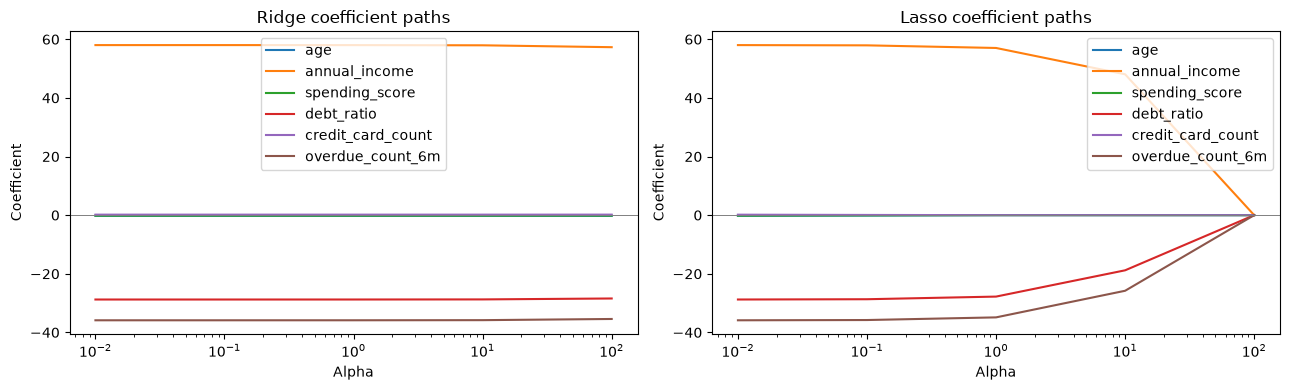

In [17]:
alpha_values = [0.01, 0.1, 1, 10, 100]
ridge_coefficients = []
lasso_coefficients = []

for alpha in alpha_values:
    ridge_pipeline = Pipeline([
        ("preprocessing", clone(numeric_preprocessor)),
        ("model", Ridge(alpha=alpha)),
    ])
    ridge_pipeline.fit(X_train, y_regression_train)
    ridge_coefficients.append(ridge_pipeline.named_steps["model"].coef_)

    lasso_pipeline = Pipeline([
        ("preprocessing", clone(numeric_preprocessor)),
        ("model", Lasso(alpha=alpha, max_iter=50_000)),
    ])
    lasso_pipeline.fit(X_train, y_regression_train)
    lasso_coefficients.append(lasso_pipeline.named_steps["model"].coef_)

ridge_coefficient_table = pd.DataFrame(ridge_coefficients, index=alpha_values, columns=feature_columns)
lasso_coefficient_table = pd.DataFrame(lasso_coefficients, index=alpha_values, columns=feature_columns)
display(lasso_coefficient_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ridge_coefficient_table.plot(ax=axes[0], logx=True, title="Ridge coefficient paths")
lasso_coefficient_table.plot(ax=axes[1], logx=True, title="Lasso coefficient paths")
for axis in axes:
    axis.set_xlabel("Alpha")
    axis.set_ylabel("Coefficient")
    axis.axhline(0, color="gray", linewidth=0.7)
plt.tight_layout()
plt.show()

**확인 질문:** Lasso의 계수가 모두 0이 되면 어떤 예측이 남을까?
<details><summary>답 확인</summary>절편만 남아 모든 고객에게 같은 점수를 예측한다. Alpha가 크면 무조건 좋은 것이 아니다. 이 데이터에서 작은 노이즈 변수는 먼저 0이 되고, 큰 Alpha에서는 신호 변수까지 줄어든다. Ridge는 이 범위에서 변화가 작을 수 있다. 손실항의 스케일이 다르기 때문이다.</details>

### 7-2. Alpha 선택 — Train 5-fold CV

그림과 Test를 보고 Alpha를 고르지 않는다. GridSearchCV에 원본 Train과 Pipeline 전체를 넘긴다. `model__alpha`는 model 단계의 alpha다. `neg_root_mean_squared_error`는 작을수록 좋은 RMSE에 마이너스를 붙여 큰 점수를 고르는 도구의 규칙에 맞춘 것이다.

In [18]:
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold

regression_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
classification_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_search = GridSearchCV(
    Pipeline([("preprocessing", clone(numeric_preprocessor)), ("model", Ridge())]),
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error", cv=regression_cv, n_jobs=1,
)
ridge_search.fit(X_train, y_regression_train)

lasso_search = GridSearchCV(
    Pipeline([("preprocessing", clone(numeric_preprocessor)),
              ("model", Lasso(max_iter=50_000))]),
    param_grid={"model__alpha": alpha_values},
    scoring="neg_root_mean_squared_error", cv=regression_cv, n_jobs=1,
)
lasso_search.fit(X_train, y_regression_train)

ridge_predictions = ridge_search.predict(X_test)
lasso_predictions = lasso_search.predict(X_test)
regression_rows.append(evaluate_regressor("Ridge CV", y_regression_test, ridge_predictions))
regression_rows.append(evaluate_regressor("Lasso CV", y_regression_test, lasso_predictions))
print("Ridge:", ridge_search.best_params_)
print("Lasso:", lasso_search.best_params_)
display(pd.DataFrame(regression_rows))

Ridge: {'model__alpha': 1}
Lasso: {'model__alpha': 0.1}


,model,rmse,mae,r2
0,Mean,80.8737,64.7302,-0.0004
1,Linear,30.1257,23.9327,0.8612
2,Ridge CV,30.1259,23.9328,0.8612
3,Lasso CV,30.1284,23.9297,0.8612


### 7-3. 출력 범위와 모델 평가

미션은 0~1000의 신용 점수 출력을 요구한다. 선형 모델은 범위 밖 숫자를 낼 수 있다. 모델의 원본 예측과, 사용자가 받는 범위 제한 출력을 구분한다. 아래 `clip`은 원본 CSV 수정이 아니라 예측 결과의 후처리다. 지표 변화도 함께 확인한다.

원본 예측의 범위 밖 개수: 0


,model,rmse,mae,r2
0,Lasso raw,30.1284,23.9297,0.8612
1,Lasso output 0–1000,30.1284,23.9297,0.8612


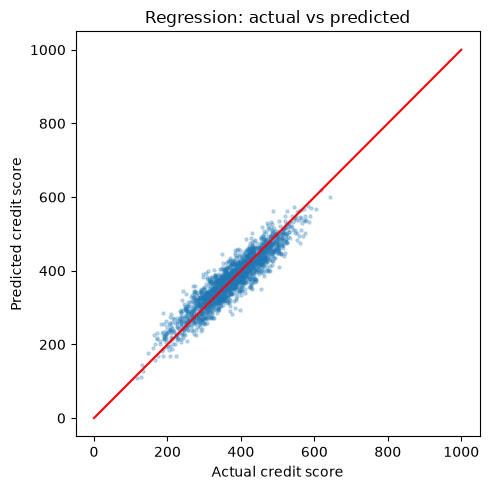

In [19]:
bounded_score_predictions = np.clip(lasso_predictions, 0, 1000)
print("원본 예측의 범위 밖 개수:", np.sum((lasso_predictions < 0) | (lasso_predictions > 1000)))
display(pd.DataFrame([
    evaluate_regressor("Lasso raw", y_regression_test, lasso_predictions),
    evaluate_regressor("Lasso output 0–1000", y_regression_test, bounded_score_predictions),
]))
assert np.all((bounded_score_predictions >= 0) & (bounded_score_predictions <= 1000))

plt.figure(figsize=(5, 5))
plt.scatter(y_regression_test, bounded_score_predictions, s=5, alpha=0.25)
plt.plot([0, 1000], [0, 1000], color="red")
plt.xlabel("Actual credit score")
plt.ylabel("Predicted credit score")
plt.title("Regression: actual vs predicted")
plt.tight_layout()
plt.show()

## 8. 앙상블 — 기본 RF → GridSearchCV

Random Forest는 여러 나무를 모아 개별 나무의 흔들림을 줄이는 방식이다. 합쳤다고 과대적합이 사라지는 것은 아니다. 먼저 기본 RF를 학습하고, **동일한 입력·전처리·class_weight**를 유지해 튜닝 전후를 비교한다. 속도보다 학습 흐름이 보이도록 탐색은 8조합 × 5-fold로 줄였다. 기존 보고서의 30조합 실험과 별개다.

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, ParameterGrid

default_forest = Pipeline([
    ("preprocessing", clone(numeric_preprocessor)),
    ("model", RandomForestClassifier(class_weight="balanced",
                                      random_state=RANDOM_STATE, n_jobs=2)),
])
default_forest_cv = cross_val_score(default_forest, X_train, y_classification_train,
                                    scoring="f1", cv=classification_cv, n_jobs=1)
default_forest.fit(X_train, y_classification_train)
print("기본 RF CV F1:", default_forest_cv.mean())

기본 RF CV F1: 0.6576629296774489


In [21]:
forest_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [8, 12],
    "model__min_samples_leaf": [1, 5],
}
print("탐색 조합:", len(ParameterGrid(forest_grid)))
forest_search = GridSearchCV(
    clone(default_forest), param_grid=forest_grid,
    scoring="f1", cv=classification_cv, n_jobs=1,
)
forest_search.fit(X_train, y_classification_train)
tuned_forest = forest_search.best_estimator_
print("선택한 설정:", forest_search.best_params_)
print("선택한 설정의 CV F1:", forest_search.best_score_)
print("기본 대비 CV F1 차이:", forest_search.best_score_ - default_forest_cv.mean())

탐색 조합: 8


선택한 설정: {'model__max_depth': 12, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
선택한 설정의 CV F1: 0.6670890061138851
기본 대비 CV F1 차이: 0.009426076436436226


In [22]:
classification_rows = [rule_result, logistic_result, balanced_result, smote_result]
default_forest_result = evaluate_classifier("RF default", default_forest, X_test, y_classification_test)
tuned_forest_result = evaluate_classifier("RF tuned", tuned_forest, X_test, y_classification_test)
classification_rows.append(default_forest_result)
classification_rows.append(tuned_forest_result)
classification_table = pd.DataFrame(classification_rows)
display(classification_table)
print("RF 튜닝 전후 Test F1 차이:", tuned_forest_result["f1"] - default_forest_result["f1"])

,model,accuracy,precision,recall,f1,roc_auc
0,Rules,0.5130,0.1947,0.9750,0.3245,0.8589
1,Logistic — no handling,0.9205,0.7077,0.5750,0.6345,0.9505
2,Logistic — class_weight,0.8785,0.4965,0.8750,0.6335,0.9505
3,Logistic — SMOTE,0.8845,0.5109,0.8750,0.6452,0.9504
4,RF default,0.9105,0.6041,0.7375,0.6642,0.9388
5,RF tuned,0.8985,0.5539,0.7917,0.6518,0.9399


RF 튜닝 전후 Test F1 차이: -0.012364074029973637


**출력 읽기:** 비교표에서 규칙 대비 학습, 단일 모델 대비 앙상블, 같은 RF의 튜닝 전후를 구분한다. Train CV에서 좋아져도 Test는 나빠질 수 있다. 그런 경우 그대로 보고하고, Test에 맞춰 격자를 다시 고치지 않는다. CV 선택 점수는 후보를 선택하는 데 사용했으므로 독립 성능 추정치로 과장하지 않는다.

**확인 질문:** RF의 F1이 높으면 AUC도 반드시 높을까?
<details><summary>답 확인</summary>아니다. F1은 현재 판정 기준의 결과이고 AUC는 위험 순위 구분 능력이다. 선형 구조의 합성 데이터라 로지스틱 회귀가 AUC에서 더 좋을 수 있다. ‘앙상블이 항상 우수하다’가 목표가 아니라 차이를 수치로 설명하는 것이 목표다.</details>

## 9. 오류를 읽기 — 혼동행렬과 ROC

혼동행렬은 실제(행)와 예측(열)의 조합이다. FP는 정상 고객을 위험하다고 잘못 거르는 오탐, FN은 연체자를 놓치는 미탐이다. ROC는 임계값을 바꿀 때 오탐률(FPR)과 재현율(TPR)이 어떻게 변하는지 보여준다.

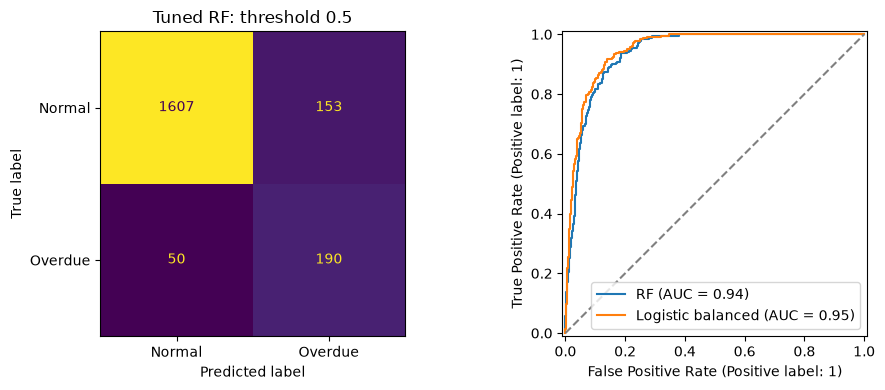

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(
    tuned_forest, X_test, y_classification_test,
    display_labels=["Normal", "Overdue"], ax=axes[0], colorbar=False,
)
axes[0].set_title("Tuned RF: threshold 0.5")
RocCurveDisplay.from_estimator(tuned_forest, X_test, y_classification_test, ax=axes[1], name="RF")
RocCurveDisplay.from_estimator(balanced_logistic, X_test, y_classification_test,
                               ax=axes[1], name="Logistic balanced")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.tight_layout()
plt.show()

### 9-1. 임계값은 Train OOF 예측으로 정하기

학습 흐름을 설명하기 위해 여기서는 튜닝한 RF를 정책 예시 모델로 고정한다. 기존 보고서의 ‘최종 모델 선택’과는 별개의 실습이다. OOF는 각 고객을 그 고객이 포함되지 않은 학습 부분으로 예측하는 방법이다. **설정은 이미 Train CV로 선택했으며, 설정 탐색까지 각 fold에서 다시 하는 중첩 교차검증은 아니다.** Test는 임계값 선택에 사용하지 않는다.

기본 0.5 대신 보류·거절 두 기준을 쓴다. 보류 기준은 OOF 재현율 95% 목표, 거절 기준은 OOF F1 최대다. 이 절차는 학습 예시이며 연체 손실액을 반영한 비용 최적화는 아니다.

In [24]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

oof_probabilities = cross_val_predict(
    clone(tuned_forest), X_train, y_classification_train,
    cv=classification_cv, method="predict_proba", n_jobs=1,
)[:, 1]

precision_values, recall_values, thresholds = precision_recall_curve(
    y_classification_train, oof_probabilities,
)
# 마지막 precision/recall에는 대응 임계값이 없으므로 [:-1]로 제외한다.
denominator = precision_values[:-1] + recall_values[:-1]
f1_values = 2 * precision_values[:-1] * recall_values[:-1] / np.clip(denominator, 1e-12, None)
reject_threshold = thresholds[np.argmax(f1_values)]
recall_target_met = recall_values[:-1] >= 0.95
hold_threshold = thresholds[recall_target_met].max()
hold_threshold = min(hold_threshold, reject_threshold)
print("보류 기준:", hold_threshold)
print("거절 기준:", reject_threshold)

보류 기준: 0.17332336138298451
거절 기준: 0.4926484065435953


In [25]:
test_risk_probabilities = tuned_forest.predict_proba(X_test)[:, 1]
policy_labels = np.full(len(X_test), "hold", dtype=object)
policy_labels[test_risk_probabilities < hold_threshold] = "approve"
policy_labels[test_risk_probabilities >= reject_threshold] = "reject"

policy_rows = []
for band_name in ["approve", "hold", "reject"]:
    band_mask = policy_labels == band_name
    customer_count = int(band_mask.sum())
    overdue_count = int(y_classification_test.to_numpy()[band_mask].sum())
    overdue_rate = overdue_count / customer_count if customer_count else np.nan
    policy_rows.append({"band": band_name, "customers": customer_count,
                        "overdue": overdue_count, "overdue_rate": overdue_rate})
display(pd.DataFrame(policy_rows))

,band,customers,overdue,overdue_rate
0,approve,1426,15,0.0105
1,hold,224,34,0.1518
2,reject,350,191,0.5457


**질문에 답해 보기:**

- 임계값을 낮추면 무엇을 얻고 무엇을 잃는가?
- 실제 서비스에서는 성능과 속도 중 무엇을 우선할까?

<details><summary>답의 방향</summary>임계값을 낮추면 일반적으로 재현율이 올라가고 오탐이 늘어난다. 미탐의 연체 손실, 오탐의 기회비용, 보류 심사 인력과 필요한 응답 시간을 함께 정해야 한다. 정해진 응답 시간을 만족하는 모델 중 기대 비용과 성능을 비교한다. 이 노트북은 추론 속도나 실제 비용을 측정하지 않았으므로 운영 우열을 단정하지 않는다. 가중치 학습 모델의 예측 점수를 보정 검증 없이 실제 연체 확률과 완전히 같다고 간주하지 않는다.</details>

## 10. 권장·보너스 — 왜 이런 결과가 나왔는가?

### 10-1. 특징 중요도

RF의 불순도 중요도는 학습 중 분할에 기여한 정도다. 값 종류가 많은 변수의 중요도가 부풀 수 있으므로 인과 효과라고 읽지 않는다. 생성 공식에 쓰인 소득·부채 비율·연체 횟수와 비교해 해석한다.

,feature,importance
1,annual_income,0.4693
5,overdue_count_6m,0.2125
3,debt_ratio,0.1694
2,spending_score,0.0632
0,age,0.0544
4,credit_card_count,0.0311


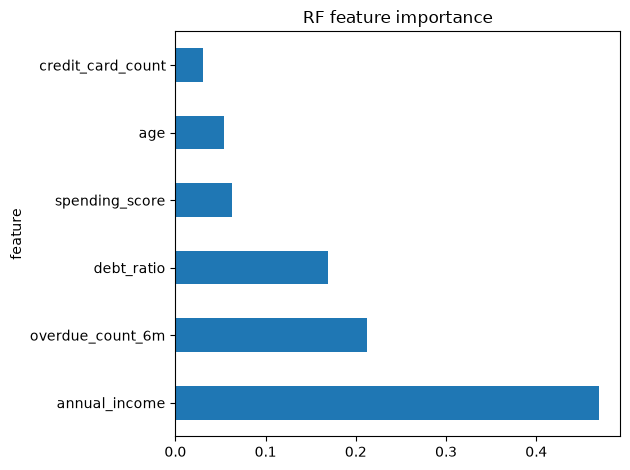

In [26]:
importance_values = tuned_forest.named_steps["model"].feature_importances_
importance_table = pd.DataFrame({"feature": feature_columns, "importance": importance_values})
importance_table = importance_table.sort_values("importance", ascending=False)
display(importance_table)
importance_table.plot.barh(x="feature", y="importance", legend=False, title="RF feature importance")
plt.tight_layout()
plt.show()

**해석할 세 가지:** ① 상위 변수는 무엇인가? ② 생성 공식에 쓰이지 않은 변수가 얼마나 쓰였는가? ③ 이 중요도가 인과관계나 실제 금융 고객의 중요도를 뜻하지 않는 이유는 무엇인가?

### 10-2. Learning Curve — 학습 데이터 양과 과대적합

Train 일부의 크기를 바꾸며 5-fold Validation 점수를 본다. Test는 사용하지 않는다. F1은 높을수록 좋고, Train과 Validation의 간격은 과대적합의 단서다. 작은 간격만 보지 말고 점수 자체도 확인한다. 학습 곡선만으로 편향과 분산을 엄밀히 분리한 것은 아니다.

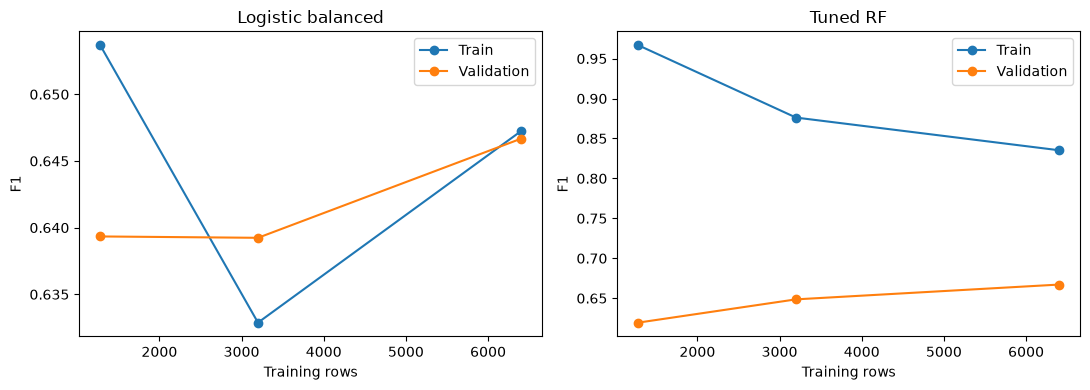

In [27]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
curve_models = [("Logistic balanced", balanced_logistic), ("Tuned RF", tuned_forest)]
for axis, (model_name, estimator) in zip(axes, curve_models):
    sizes, train_scores, validation_scores = learning_curve(
        clone(estimator), X_train, y_classification_train,
        train_sizes=[0.2, 0.5, 1.0], cv=classification_cv, scoring="f1", n_jobs=1,
    )
    axis.plot(sizes, train_scores.mean(axis=1), marker="o", label="Train")
    axis.plot(sizes, validation_scores.mean(axis=1), marker="o", label="Validation")
    axis.set_title(model_name)
    axis.set_xlabel("Training rows")
    axis.set_ylabel("F1")
    axis.legend()
plt.tight_layout()
plt.show()

## 11. 보너스 — 범주형 처리와 Custom Transformer

지금까지 원본 6개는 모두 수치형이었다. 미션의 범주형 처리 경로도 실제로 경험하기 위해 연령대를 만든다. 부채액도 함께 추가한다. CSV를 바꾸지 않고 Pipeline 내부에서 계산한다. 이는 **입력 설계가 바뀌는 별도 확장 실험**이며 앞의 모델과 같은 수치가 나와야 하는 실험은 아니다.

먼저 함수를 직접 보고 ‘입력 표 → 새 열이 추가된 표’를 이해한 뒤, 같은 처리를 `fit/transform` 규약에 맞춘 클래스에 연결한다. 연령대는 여기서 인코딩을 경험하기 위한 예시이고, 실제 금융에서 연령 사용의 적절성을 입증한 것은 아니다.

In [28]:
def add_derived_features(input_frame):
    result = input_frame.copy()
    age_bins = [20, 30, 40, 50, 60, 70]
    age_labels = ["20-29", "30-39", "40-49", "50-59", "60-69"]
    age_groups = pd.cut(result["age"], bins=age_bins, labels=age_labels, right=False)
    result["age_group"] = age_groups.astype(object).where(age_groups.notna(), np.nan)
    result["debt_amount"] = result["annual_income"] * result["debt_ratio"]
    return result

display(add_derived_features(X_train.head()))

,age,annual_income,spending_score,debt_ratio,credit_card_count,overdue_count_6m,age_group,debt_amount
1559,40,4613.0,16,0.98,7,0,40-49,4520.74
7318,40,5914.0,57,0.83,1,0,40-49,4908.62
4825,22,3466.0,11,0.90,2,0,20-29,3119.40
606,49,5333.0,17,0.48,9,0,40-49,2559.84
2383,38,1500.0,27,0.82,8,0,30-39,1230.00


In [29]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

class LearningDerivedFeatures(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        # 이 변환은 통계량을 배우지 않는다. Pipeline의 학습 규약에 맞춰 self를 반환한다.
        return self

    def transform(self, X):
        return add_derived_features(X)

numeric_columns = feature_columns + ["debt_amount"]
categorical_columns = ["age_group"]
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
column_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_preprocessor), numeric_columns),
    ("categorical", categorical_preprocessor, categorical_columns),
])
extended_logistic = Pipeline([
    ("derive", LearningDerivedFeatures()),
    ("columns", column_preprocessor),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000,
                                 random_state=RANDOM_STATE)),
])
extended_logistic.fit(X_train, y_classification_train)
display(extended_logistic.named_steps["columns"].get_feature_names_out())
display(pd.DataFrame([evaluate_classifier("Extended logistic", extended_logistic,
                                         X_test, y_classification_test)]))

array(['numeric__age', 'numeric__annual_income',
       'numeric__spending_score', 'numeric__debt_ratio',
       'numeric__credit_card_count', 'numeric__overdue_count_6m',
       'numeric__debt_amount', 'categorical__age_group_20-29',
       'categorical__age_group_30-39', 'categorical__age_group_40-49',
       'categorical__age_group_50-59', 'categorical__age_group_60-69'],
      dtype=object)

,model,accuracy,precision,recall,f1,roc_auc
0,Extended logistic,0.877,0.493,0.875,0.6306,0.9495


**출력 읽기:** `age_group_20-29` 같은 새 입력 열이 생겼는지 본다. 전처리기는 연령대 문자열을 모델이 쓸 숫자로 바꾼다. 실제 범주형 자료에 일반 SMOTE를 바로 확장하면 원-핫 값 사이의 합성 문제가 생길 수 있으므로, 앞 SMOTE 실험은 원본 수치형 입력에 한정했다.

### 11-1. 기존 src 모듈과 연결

처음부터 거대한 함수 한 줄을 외우는 대신, 앞에서 이해한 작업이 어디로 이동했는지 확인한다. 아래 기존 전처리와 같은 입력을 넣고, 기존 규칙·분할이 학습용 구현과 같은지도 확인한다. 기존 Custom Transformer는 입력 검사와 변수 이름 제공 등 재사용을 위한 규약을 더 갖췄다.

In [30]:
from src.features import build_preprocessor
from src.baseline import rule_hits, rule_based_predict
from src.data import split_data

module_preprocessor = build_preprocessor()
module_prepared_train = module_preprocessor.fit_transform(X_train)
learning_prepared_train = extended_logistic.named_steps["columns"].transform(
    extended_logistic.named_steps["derive"].transform(X_train)
)
np.testing.assert_allclose(module_prepared_train, learning_prepared_train, atol=1e-10)
np.testing.assert_array_equal(rule_predictions, X_test.apply(rule_based_predict, axis=1))
np.testing.assert_array_equal(rule_scores, rule_hits(X_test).sum(axis=1))
module_split = split_data(customers)
np.testing.assert_array_equal(module_split.X_test.index, X_test.index)
print("기존 모듈과 전처리·규칙·분할 일치 확인 완료")

기존 모듈과 전처리·규칙·분할 일치 확인 완료


| 직접 실행한 작업 | 기존 프로젝트에서 찾을 곳 |
| --- | --- |
| CSV 로딩·분할 | `src/data.py` |
| if문과 규칙별 점수 | `src/baseline.py` |
| 파생 변수·ColumnTransformer | `src/features.py` |
| Ridge/Lasso·Alpha 탐색 | `src/regression.py` |
| 분류 학습·탐색·정책 | `src/classification.py` |
| 중요도·학습 곡선 | `src/diagnostics.py` |
| 결과를 그림·문서로 만들기 | `src/report.py` |

학습용 노트북의 펼친 코드는 설명을 위한 것이다. 기존 CLI·최종 보고서는 계속 src 모듈을 사용한다. 실험 로직을 수정할 때는 두 결과의 차이를 확인해야 한다. 기존 `fit_models`는 여러 후보를 한 형식으로 실행하는 더 큰 반복 구조다.

**확인 질문:** 공통 전처리를 쓴다는 것은 이미 학습한 스케일러 하나를 모든 CV fold에 돌려 쓴다는 뜻일까?
<details><summary>답 확인</summary>아니다. 전처리의 설계와 만드는 코드를 공유한다. Pipeline과 교차검증은 각 학습 부분에서 필요한 통계량을 별도로 fit해야 한다.</details>

## 12. 학습 정리

처음의 원본 입력에서 최종 예측까지 데이터가 어떻게 바뀌었는지 되짚어 본다. 학습 데이터로 기준을 정한 단계와 평가 데이터에 적용한 단계를 구분한다. 회귀와 분류 결과를 각 지표의 단위와 의미로 설명하고, 관측 결과와 운영 가정을 구분한다.

**발표 마무리 예시:** ‘같은 입력이어도 회귀와 분류는 정답·평가지표가 다릅니다. 규칙 대비 학습의 효과를 수치로 확인했고, 불균형과 규제는 각각 다른 문제를 다룹니다. 앙상블은 모든 지표의 승자가 아니며, 최종 운영 기준에는 오탐·미탐 비용과 응답 시간이 필요합니다.’

기존 `analysis_report.ipynb`와 README의 수치는 파생 변수와 더 큰 탐색을 포함한다. 이 실습의 원본 6개 기반·8조합 탐색 결과와 섞어 보고하지 않는다. RF+SMOTE와 XGBoost의 추가 비교, 1-표준오차 모델 선택은 기존 보고서에서 이어 본다. 해당 기법 모두를 사용하는 것은 필수 요건이 아니다.

### 실험 변경 시 지킬 경계

학습을 위해 모델과 임계값을 바꿔 Test를 반복 관찰하면 Test는 점점 개발용 자료가 된다. 현재 수치는 합성 데이터 실습 결과다. 새 방식의 일반화 성능을 엄밀히 비교하려면 별도의 미사용 평가 자료나 중첩 검증이 필요하다. 원본 데이터는 임의로 수정하지 않는다.

제출 전 README의 성능표·실행법과 requirements.txt를 확인하고, CSV 제외 규칙과 기능 단위 Git 이력도 점검한다.